# Analisis Tingkat Suicide Pada Tahun 2010-2012

Disusun oleh:
    - Nama   : Argreisto Daniel Krismiawan
    - NIM    : 241011400910
    - Kelas  : 05TPLP023
    - Metode : Klasifikasi, Regresi, Clustering
    - Tujuan : Analisis dan prediski tingkat suicide rate pada tahun 2010–2012

Data diambil dari Kaggle : Suicide Rates Overview 1985 to 2016 (master.csv).

Data aslinya ada 27.820 baris, saya ambil tahun 2010-2012 supaya jumlahnya sekitar 3.000 baris

Link : https://www.kaggle.com/datasets/russellyates88/suicide-rates-overview-1985-to-2016

## 1. Memahami Data

In [1]:
# import library
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

In [2]:
# baca file master.csv
raw = pd.read_csv("master.csv")
raw.columns = raw.columns.str.strip()
print("Ukuran data asli:", raw.shape)

Ukuran data asli: (27820, 12)


In [3]:
# ambil data tahun 2010 - 2012
df = raw[(raw["year"] >= 2010) & (raw["year"] <= 2012)].copy()
print("Ukuran setelah filter 2010-2012:", df.shape)

Ukuran setelah filter 2010-2012: (3060, 12)


In [4]:
# cek berapa negara dan baris tahun
print("Jumlah negara:", df["country"].nunique())
print(df["year"].value_counts().sort_index())

Jumlah negara: 92
2010    1056
2011    1032
2012     972
Name: year, dtype: int64


In [5]:
df.head()

,country,year,sex,age,suicides_no,population,suicides/100k pop,country-year,HDI for year,gdp_for_year ($),gdp_per_capita ($),generation
252,Albania,2010,male,55-74 years,20,241852,8.27,Albania2010,0.722,"11,926,953,259",4359,Silent
253,Albania,2010,male,35-54 years,20,371611,5.38,Albania2010,0.722,"11,926,953,259",4359,Generation X
254,Albania,2010,male,25-34 years,9,179720,5.01,Albania2010,0.722,"11,926,953,259",4359,Generation X
255,Albania,2010,male,75+ years,2,50767,3.94,Albania2010,0.722,"11,926,953,259",4359,Silent
256,Albania,2010,male,15-24 years,10,279508,3.58,Albania2010,0.722,"11,926,953,259",4359,Millenials


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3060 entries, 252 to 27795
Data columns (total 12 columns):
country               3060 non-null object
year                  3060 non-null int64
sex                   3060 non-null object
age                   3060 non-null object
suicides_no           3060 non-null int64
population            3060 non-null int64
suicides/100k pop     3060 non-null float64
country-year          3060 non-null object
HDI for year          2916 non-null float64
gdp_for_year ($)      3060 non-null object
gdp_per_capita ($)    3060 non-null int64
generation            3060 non-null object
dtypes: float64(2), int64(4), object(6)
memory usage: 239.1+ KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,3060.0,2.010973e+03,8.137616e-01,2010.000,2010.00,2011.000,2.012000e+03,2.012000e+03
suicides_no,3060.0,2.305052e+02,7.990337e+02,0.000,3.00,23.000,1.170000e+02,1.176700e+04
population,3060.0,1.929239e+06,4.120357e+06,956.000,101254.25,463018.500,1.587787e+06,4.279850e+07
suicides/100k pop,3060.0,1.121364e+01,1.668826e+01,0.000,0.91,5.100,1.463750e+01,1.870600e+02
HDI for year,2916.0,7.979259e-01,8.639522e-02,0.611,0.73,0.809,8.810000e-01,9.420000e-01
gdp_per_capita ($),3060.0,2.555152e+04,2.456112e+04,991.000,7498.00,14827.000,4.118400e+04,1.227290e+05


**Jenis variabel**
- Kontinu: population, suicides_no, suicides/100k pop, HDI for year, gdp_per_capita, gdp_for_year
- Nominal: country, generation
- Biner: sex
- Ordinal: age (5-14 < 15-24 < 25-34 < 35-54 < 55-74 < 75+)
- Waktu: year

Hasilnya data asli 27.820 baris dan 12 kolom. Setelah difilter jadi 3.060 baris dengan 92 negara (2010 ada 1.056 baris, 2011 ada 1.032, 2012 ada 972).

Satu baris itu mewakili satu kelompok (negara, tahun, jenis kelamin, kelompok umur), bukan satu orang. Kolom HDI for year ada 144 baris yang kosong.

**Penjelasan kolom**
- **suicides_no**: jumlah kasus bunuh diri di kelompok itu.
- **population**: jumlah penduduk di kelompok itu.
- **suicides/100k pop**: jumlah kasus per 100 ribu penduduk. Rumusnya suicides_no dibagi population terus dikali 100.000. Kolom ini dipakai jadi target karena bisa dibandingin dengan adil antar negara. Kalau pakai jumlah kasus aja, negara besar pasti kelihatan lebih parah.
- **gdp_per_capita**: rata-rata pendapatan ekonomi per orang di negara itu pada tahun tersebut dalam dolar. Makin besar berarti rata-rata penduduknya makin makmur.
- **gdp_for_year**: total ekonomi seluruh negara dalam setahun dalam dolar.
- **year**: tahun pencatatan. Di data ini cuma ada 2010, 2011, dan 2012.
- **HDI for year**: indeks pembangunan manusia, nilainya 0 sampai 1 (gabungan kesehatan, pendidikan, dan pendapatan). Ada 144 baris yang kosong.

**Target label**
- Klasifikasi: kolom risk (Tinggi atau Rendah) yang kubikin dari suicides/100k pop. Kalau angkanya di atas median data latih dianggap Tinggi (1), kalau tidak ya Rendah (0). Jenisnya kategorik biner (binomial) karena cuma ada dua kemungkinan.
- Regresi: suicides/100k pop langsung. Jenisnya numerik kontinu karena bisa berkoma.
- Clustering: tidak ada target, makanya disebut tanpa label.

**Fitur**
- Numerik: year, population, gdp_per_capita, gdp_for_year, HDI for year
- Nominal (kategori tanpa urutan): country
- Biner: sex
- Ordinal (kategori ada urutan): age, urutannya 5-14 < 15-24 < 25-34 < 35-54 < 55-74 < 75+

Yang tidak dipakai jadi fitur: suicides_no dan suicides/100k pop (targetnya dari situ, nanti bocor), country-year (cuma gabungan country sama year), dan generation (turunan dari umur, isinya mirip age).

Kolom numerik perlu discaling biar skalanya sama (population bisa jutaan, HDI cuma 0 sampai 1). Nominal sama biner di one-hot biar model tidak berpikir ada urutan antar negara. Ordinal dikasih angka sesuai urutan umurnya.

## 2. Cleaning (sebelum split)

In [8]:
# gdp_for_year diubah ke angka
df["gdp_for_year ($)"] = df["gdp_for_year ($)"].astype(str).str.replace(",", "").astype(float)

In [9]:
# cek HDI yang kosong, dan buang kolom country-year
print("HDI kosong (%):", round(df["HDI for year"].isnull().mean()*100, 1))
df = df.drop(columns=["country-year"])

HDI kosong (%): 4.7


In [10]:
# cek duplikat
print("Duplikat:", df.duplicated().sum())
df = df.drop_duplicates()

Duplikat: 0


In [11]:
# cek missing value
print("Missing value:\n", df.isnull().sum())
print("Ukuran setelah cleaning:", df.shape)

Missing value:
 country                 0
year                    0
sex                     0
age                     0
suicides_no             0
population              0
suicides/100k pop       0
HDI for year          144
gdp_for_year ($)        0
gdp_per_capita ($)      0
generation              0
dtype: int64
Ukuran setelah cleaning: (3060, 11)


Hasilnya duplikat 0, HDI kosong 144 baris (4,7%), dan ukuran data sekarang 3.060 baris dengan 11 kolom.

## 3. EDA (Exploratory Data Analysis)

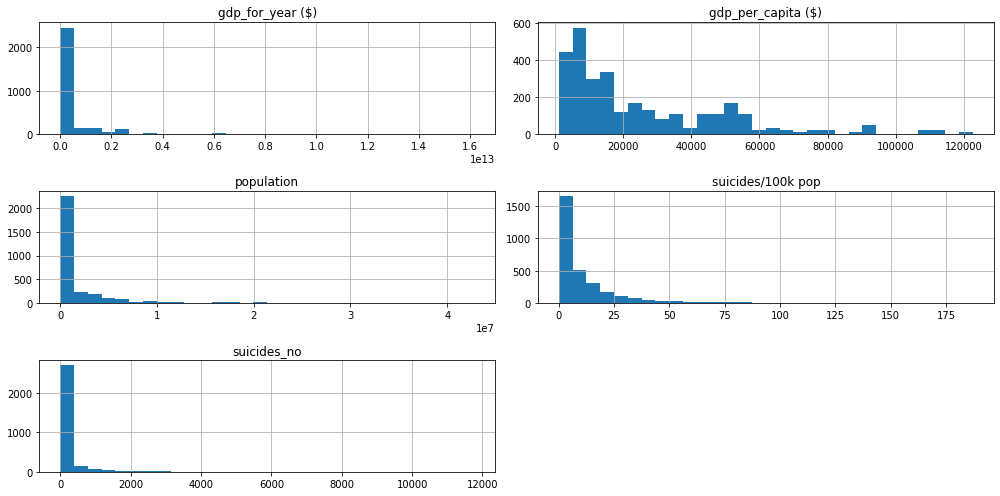

In [12]:
# Histogram 
num_eda = ["suicides_no", "population", "suicides/100k pop", "gdp_per_capita ($)", "gdp_for_year ($)"]
df[num_eda].hist(figsize=(14,7), bins=30); plt.tight_layout(); plt.show()

In [13]:
# hitung skewness (ukuran seberapa miring datanya)
print(df[num_eda].skew().round(2))

suicides_no           7.99
population            4.56
suicides/100k pop     3.32
gdp_per_capita ($)    1.50
gdp_for_year ($)      6.30
dtype: float64


Grafik histogram buat liat sebaran nilai tiap kolom angka. Nilainya dibagi jadi 30 kelompok, makin tinggi batangnya berarti makin banyak baris di kelompok itu.

Skewness itu ukuran miringnya. Mendekati 0 berarti simetris, positif miring ke kanan, negatif miring ke kiri, dan di atas 1 dianggap miring banget. Semua kolom di output hasilnya positif. Kolom yang jarak rata-rata sama mediannya jauh biasanya skewness-nya paling gede. Dari output, suicides_no 7,99, gdp_for_year 6,30, population 4,56, suicides/100k pop 3,32, dan gdp_per_capita 1,50, jadi semuanya di atas 1.

Hasilnya semua kolomnya miring ke kanan. Banyak nilai kecil numpuk di kiri, terus ada sedikit nilai gede yang ekornya panjang ke kanan. Kelihatan juga dari angkanya: suicides/100k pop rata-ratanya 11,21 tapi mediannya cuma 5,1. suicides_no rata-ratanya 230 tapi mediannya cuma 23. population rata-ratanya 1,9 juta tapi mediannya 463 ribu. Kalau datanya miring begini, rata-rata ketarik sama nilai gede, makanya median lebih pas dijadiin patokan.

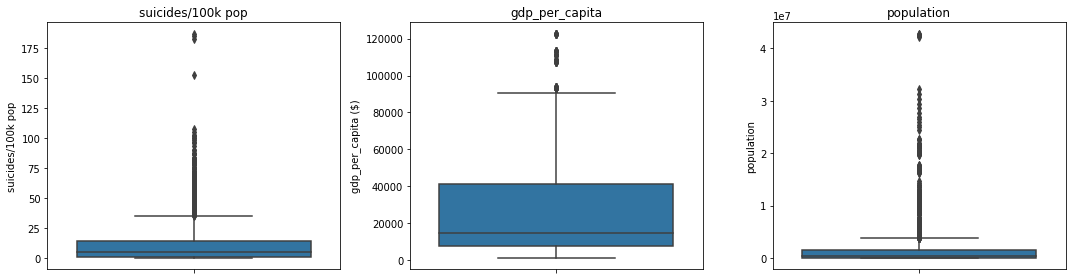

In [14]:
# Boxplot buat liat outlier
fig, ax = plt.subplots(1, 3, figsize=(15,4))
sns.boxplot(y=df["suicides/100k pop"], ax=ax[0]); ax[0].set_title("suicides/100k pop")
sns.boxplot(y=df["gdp_per_capita ($)"], ax=ax[1]); ax[1].set_title("gdp_per_capita")
sns.boxplot(y=df["population"], ax=ax[2]); ax[2].set_title("population")
plt.tight_layout(); plt.show()

Kotaknya itu 50% data yang di tengah. Garis di dalam kotak adalah median. Garis yang keluar dari kotak (kumis namanya) menunjukkan batas wajar. Titik-titik di luar kumis dianggap outlier.

Hasilnya di suicides/100k pop dan population banyak titik di atas kumis. Karena 75% data rate di bawah 14,6 dan nilai maksimumnya 187 maka wajar. Di gdp_per_capita titiknya paling sedikit karena 75% datanya di bawah sekitar 41 ribu dan maksimumnya 122 ribu.

In [15]:
# hitung outlier pakai IQR
for kol in ["suicides/100k pop", "population", "gdp_per_capita ($)"]:
    q1, q3 = df[kol].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[kol] < q1 - 1.5*iqr) | (df[kol] > q3 + 1.5*iqr)).sum()
    print(kol, "| outlier:", n_out, "| persen:", round(n_out/len(df)*100, 1))

suicides/100k pop | outlier: 229 | persen: 7.5
population | outlier: 442 | persen: 14.4
gdp_per_capita ($) | outlier: 96 | persen: 3.1


IQR itu selisih Q3 sama Q1, nilai yang kurang dari Q1 dikurangi 1,5 x IQR atau lebih dari Q3 ditambah 1,5 x IQR dianggap outlier. Jumlah dan persentasenya ada di output. Hasilnya suicides/100k pop ada 229 outlier (7,5%), population 442 (14,4%), dan gdp_per_capita 96 (3,1%).

Outlier ini tidak dibuang. Itu nilai asli data dan kalau dibuang, kelompok dengan angka tinggi yang hilang. Model Decision Tree dan Random Forest juga tidak terlalu terganggu sama outlier.

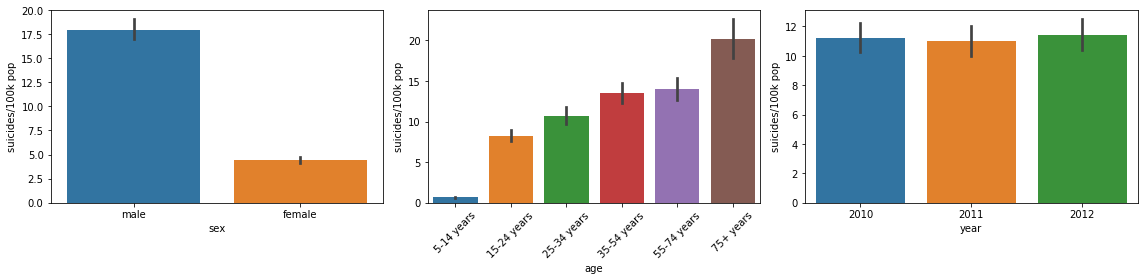

In [16]:
# bandingkan rata-rata angka suicide
order = ["5-14 years","15-24 years","25-34 years","35-54 years","55-74 years","75+ years"]
fig, ax = plt.subplots(1, 3, figsize=(16,4))
sns.barplot(x="sex", y="suicides/100k pop", data=df, ax=ax[0])
sns.barplot(x="age", y="suicides/100k pop", data=df, order=order, ax=ax[1]); ax[1].tick_params(axis="x", rotation=45)
sns.barplot(x="year", y="suicides/100k pop", data=df, ax=ax[2])
plt.tight_layout(); plt.show()

In [17]:
print(df.groupby("sex")["suicides/100k pop"].mean().round(2))
print(df.groupby("age")["suicides/100k pop"].mean().reindex(order).round(2))
print(df.groupby("year")["suicides/100k pop"].mean().round(2))

sex
female     4.42
male      18.01
Name: suicides/100k pop, dtype: float64
age
5-14 years      0.64
15-24 years     8.26
25-34 years    10.73
35-54 years    13.53
55-74 years    13.98
75+ years      20.14
Name: suicides/100k pop, dtype: float64
year
2010    11.22
2011    11.02
2012    11.42
Name: suicides/100k pop, dtype: float64


Hasilnya laki-laki rata-ratanya jauh di atas perempuan. Umur angkanya naik, paling kecil di 5-14 tahun dan paling tinggi di 75+. Antar tahun (2010, 2011, 2012) angkanya hampir sama, jadi tahun kayaknya tidak banyak pengaruh. Ini cocok sama heatmap yang nunjukin korelasi year dengan rate hampir 0.

Dari output, perempuan 4,42 dan laki-laki 18,01 (sekitar 4 kali lipat). Umur naik dari 0,64 (5-14 tahun) ke 20,14 (75+). Tahun 2010 11,22, 2011 11,02, dan 2012 11,42.

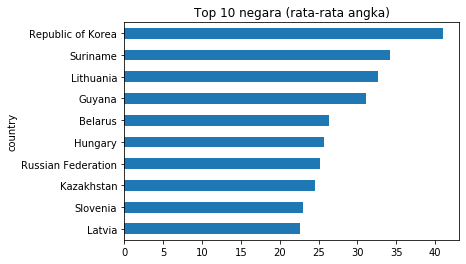

In [18]:
# 10 negara paling tinggi angka rata-ratanya
df.groupby("country")["suicides/100k pop"].mean().sort_values(ascending=False).head(10).plot(kind="barh", title="Top 10 negara (rata-rata angka)")
plt.gca().invert_yaxis(); plt.show()

In [19]:
df.groupby("country")["suicides/100k pop"].mean().sort_values(ascending=False).head(10).round(2)

country
Republic of Korea     41.01
Suriname              34.24
Lithuania             32.70
Guyana                31.13
Belarus               26.31
Hungary               25.75
Russian Federation    25.12
Kazakhstan            24.60
Slovenia              22.97
Latvia                22.66
Name: suicides/100k pop, dtype: float64

Hasilnya nama negara dan angkanya ada di output. Lima teratas: Republic of Korea 41,01, Suriname 34,24, Lithuania 32,70, Guyana 31,13, dan Belarus 26,31. Perlu diingat ini rata-rata per 100 ribu penduduk, bukan jumlah orang, jadi negara yang penduduknya sedikit juga bisa masuk. Negara-negara ini kemungkinan besar nanti banyak masuk ke cluster dengan angka tertinggi di bagian clustering.

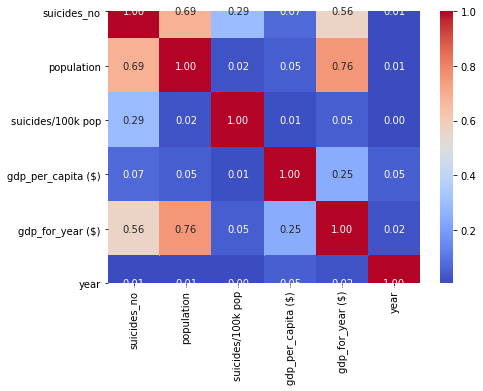

In [20]:
# Heatmap
plt.figure(figsize=(7,5))
sns.heatmap(df[num_eda + ["year"]].corr(), annot=True, fmt=".2f", cmap="coolwarm"); plt.show()

Mendekati 1 (merah) artinya naik bareng, mendekati -1 artinya yang satu naik yang satunya turun, dan mendekati 0 (biru) artinya hampir tidak ada hubungan lurus. Diagonalnya pasti 1 karena kolom dibandingin sama dirinya sendiri.

Hasilnya
- Naik bareng: population dan gdp_for_year (0,76), suicides_no dan population (0,69), suicides_no dan gdp_for_year (0,56).
- Hubungan lemah: suicides_no dan suicides/100k pop (0,29), gdp_per_capita dan gdp_for_year (0,25).
- Hampir tidak berhubungan: suicides/100k pop dengan population, gdp_per_capita, gdp_for_year, dan year, semuanya sekitar 0,00 sampai 0,05. Year juga hampir 0 sama semua kolom karena datanya cuma tiga tahun.
- Tidak ada korelasi negatif yang kuat.

Rate hampir tidak punya hubungan lurus sama kolom angka yang lain. Kemungkinan itu sebabnya Linear Regression nilainya paling rendah dan model yang bisa nangkep pola tidak lurus kayak Random Forest lebih bagus. Heatmap ini juga cuma nangkep hubungan lurus, jadi pola yang tidak lurus tidak kelihatan di sini.

In [21]:
# cek multikolinearitas: pasangan kolom fitur angka yang korelasinya paling tinggi
fitur_angka = ["year", "population", "gdp_per_capita ($)", "gdp_for_year ($)", "HDI for year"]
kor = df[fitur_angka].corr().abs()
pasangan = kor.where(np.triu(np.ones(kor.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(pasangan.head(6).round(2))

gdp_per_capita ($)  HDI for year        0.79
population          gdp_for_year ($)    0.76
gdp_for_year ($)    HDI for year        0.30
gdp_per_capita ($)  gdp_for_year ($)    0.25
population          HDI for year        0.10
year                HDI for year        0.05
dtype: float64


Hasilnya pasangan teratas ada di output. gdp_per_capita dan HDI paling tinggi (0,79), lalu population dan gdp_for_year (0,76). Sisanya di bawah 0,30.

Kolom yang mirip bikin koefisien Linear dan Logistic Regression susah dibaca karena pengaruhnya kebagi-bagi, tapi Decision Tree dan Random Forest tidak terlalu keganggu.

## 4. Split Data (80% train, 20% test)

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
# suicides_no sama suicides/100k pop tidak dipakai jadi fitur soalnya targetnya dari situ, nanti jadi bocor
num_cols = ["year", "population", "gdp_per_capita ($)", "gdp_for_year ($)", "HDI for year"]
nom_cols = ["country", "sex"]
ord_cols = ["age"]
X = df[num_cols + nom_cols + ord_cols]
y_reg = df["suicides/100k pop"]

In [24]:
X_train, X_test, y_reg_train, y_reg_test = train_test_split(X, y_reg, test_size=0.2, random_state=1)

In [25]:
# bikin target klasifikasi: kalau angkanya diatas median data latih berarti Tinggi (1), kalau dibawah Rendah (0)
median_train = y_reg_train.median()
y_train = (y_reg_train > median_train).astype(int)
y_test = (y_reg_test > median_train).astype(int)
print("Median train:", round(median_train, 2))
print("Kelas train:", y_train.value_counts().to_dict(), "| Kelas test:", y_test.value_counts().to_dict())

Median train: 4.97
Kelas train: {0: 1225, 1: 1223} | Kelas test: {1: 316, 0: 296}


Model harus dites pakai data yang belum pernah dilihat.  
Median dihitung dari data train saja supaya data test tidak ikut ngintip.  
Kolom suicides_no dan suicides/100k pop tidak dipakai sebagai fitur karena target berasal dari angka itu, kalau dipakai modelnya jadi bocor.

Hasilnya median train 4,97.  
Data train 2.448 baris, isinya 1.225 Rendah dan 1.223 Tinggi.  
Data test 612 baris, isinya 316 Tinggi dan 296 Rendah.

Kelasnya masih seimbang (sekitar 50:50), jadi accuracy tetap adil dipakai buat menilai model.

## 5. Preprocessing

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

In [27]:
# urut dari muda ke tua
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("nom", OneHotEncoder(handle_unknown="ignore"), nom_cols),
    ("ord", OrdinalEncoder(categories=[order]), ord_cols),
])

Untuk kolom angka, HDI yang kosong diisi median lalu di-scaling pakai StandardScaler. Kolom country dan sex pakai OneHotEncoder. Kolom age pakai OrdinalEncoder karena kelompok umurnya ada urutan.

one-hot dipakai supaya model tidak mengira ada urutan antar negara. Umur pakai ordinal karena memang berurutan dari muda ke tua. Scaling perlu karena skala kolomnya beda jauh (population sampai jutaan, HDI cuma 0 sampai 1), apalagi buat KNN yang hitungannya pakai jarak.

## Model yang Dipakai

Yang dimodelkan hubungan antara faktor demografi dan ekonomi (negara, jenis kelamin, kelompok umur, tahun, populasi, GDP per kapita, GDP total, dan HDI) dengan angka bunuh diri per 100 ribu penduduk. Datanya bisa dimodelkan karena bentuknya tabel, jumlahnya 3.060 baris, fiturnya campuran angka dan kategori, dan sudah dibersihkan.

Karakteristik tiap model yang dipakai:

**Logistic Regression** (klasifikasi). Menghitung peluang sebuah data masuk ke kelas Tinggi memakai garis lurus yang diubah jadi peluang. Kelebihannya cepat dan gampang dijelaskan. Kekurangannya kurang cocok kalau hubungan antar kolom tidak lurus. Perlu scaling. Di sini dipakai sebagai pembanding paling dasar.

**Linear Regression** (regresi). Konsepnya mirip Logistic Regression tapi hasilnya angka, bukan kategori. Sederhana dan jadi pembanding dasar untuk regresi. Kekurangannya sama, hanya menangkap hubungan yang lurus.

**Decision Tree** (klasifikasi dan regresi). Bekerja seperti rangkaian pertanyaan ya atau tidak yang bercabang kayak pohon, misalnya "GDP di atas sekian?". Kelebihannya mudah dibaca dan tidak wajib scaling. Kekurangannya gampang overfit (hafal data latih) kalau pohonnya terlalu dalam, makanya kedalamannya dibatasi max_depth=8.

**KNN** (klasifikasi dan regresi). Melihat K data tetangga terdekat, lalu kelasnya diambil dari suara terbanyak (atau rata-ratanya untuk regresi). Tidak ada proses belajar di awal dan konsepnya gampang. Kekurangannya sensitif terhadap skala (jadi wajib scaling), lambat kalau datanya besar, dan hasilnya bergantung pada nilai K.

**Random Forest** (klasifikasi dan regresi). Gabungan banyak Decision Tree (di sini 300) yang dilatih dari sampel data yang berbeda, lalu hasilnya digabung lewat voting atau rata-rata. Biasanya lebih akurat dan lebih stabil dari satu pohon, dan lebih tahan overfit. Kekurangannya lebih susah dijelaskan dan lebih berat dihitung.

**K-Means** (clustering). Menentukan K titik pusat, tiap negara masuk ke pusat terdekat, lalu pusatnya digeser berulang sampai stabil. Cepat dan sederhana. Kekurangannya jumlah cluster harus ditentukan sendiri, sensitif terhadap skala dan outlier, dan hasil cluster cenderung berbentuk bulat.

**Hierarchical Clustering (Ward)** (clustering). Menggabungkan negara yang paling mirip sedikit demi sedikit, hasilnya digambar sebagai dendrogram. Tidak perlu menentukan jumlah cluster di awal. Kekurangannya berat kalau datanya besar, tapi di sini hanya 92 negara jadi aman.

**PCA.** Meringkas beberapa kolom jadi 2 sumbu supaya hasil cluster bisa digambar. Di sini cuma dipakai untuk visualisasi, bukan untuk modeling.

## 6. Klasifikasi (target: risiko Tinggi atau Rendah)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [29]:
# cari K terbaik buat KNN
cv_knn = {}
for k in [3, 5, 7, 9, 11, 15]:
    cv_knn[k] = cross_val_score(Pipeline([("prep", prep), ("m", KNeighborsClassifier(n_neighbors=k))]), X_train, y_train, cv=5).mean()
    print("K =", k, "| akurasi CV =", round(cv_knn[k], 3))
best_k = max(cv_knn, key=cv_knn.get)
print("K terbaik:", best_k)

K = 3 | akurasi CV = 0.882
K = 5 | akurasi CV = 0.866
K = 7 | akurasi CV = 0.859
K = 9 | akurasi CV = 0.85
K = 11 | akurasi CV = 0.843
K = 15 | akurasi CV = 0.828
K terbaik: 3


Hasilnya K=3 paling bagus (akurasi CV 0,882), makin besar K makin turun sampai 0,828 di K=15, jadi K=3 yang dipakai buat KNN.

In [30]:
# bikin empat model klasifikasi
clf_models = {
    "Logistic Regression": LogisticRegression(solver="lbfgs", max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=1),
    "KNN": KNeighborsClassifier(n_neighbors=best_k),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=1),
}
rows, preds, fitted = [], {}, {}
for name, m in clf_models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
    p = pipe.predict(X_test); preds[name] = p; fitted[name] = pipe
    rows.append([name, accuracy_score(y_test,p), precision_score(y_test,p), recall_score(y_test,p), f1_score(y_test,p)])

In [31]:
# tabel perbandingan empat model
hasil_clf = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1"]).round(3)
hasil_clf.sort_values("F1", ascending=False)

,Model,Accuracy,Precision,Recall,F1
3,Random Forest,0.904,0.933,0.877,0.904
2,KNN,0.894,0.920,0.870,0.894
1,Decision Tree,0.873,0.865,0.892,0.879
0,Logistic Regression,0.833,0.852,0.820,0.835


Tiap tebakan model masuk ke salah satu dari empat kemungkinan (positif di sini artinya risiko Tinggi): bener nebak Tinggi (TP), bener nebak Rendah (TN), salah nebak Tinggi padahal aslinya Rendah (FP), dan salah nebak Rendah padahal aslinya Tinggi (FN).

- Accuracy: dari semua tebakan, berapa persen yang benar. Karena kelas kita seimbang (316 Tinggi dan 296 Rendah di data uji), accuracy adil dipakai.
- Precision: dari semua yang ditebak Tinggi, berapa yang beneran Tinggi. Kalau kecil, berarti model sering salah nuduh.
- Recall: dari semua yang aslinya Tinggi, berapa yang berhasil ketangkep. Kalau kecil, banyak yang lolos.
- F1: gabungan precision dan recall (2 x P x R / (P + R)). Kalau salah satunya jelek, F1 ikut turun, jadi lebih jujur daripada ngeliat satu angka aja.

Random Forest kepilih jadi model terbaik karena F1-nya paling tinggi (0,904), di atas KNN 0,894, Decision Tree 0,879, dan Logistic Regression 0,835.

In [32]:
# cek overfit dengan bandingin accuracy di data latih sama di data uji, 
rows = []
for name, pipe in fitted.items():
    acc_tr = accuracy_score(y_train, pipe.predict(X_train))
    acc_te = accuracy_score(y_test, pipe.predict(X_test))
    rows.append([name, acc_tr, acc_te, acc_tr - acc_te])
pd.DataFrame(rows, columns=["Model", "Accuracy train", "Accuracy test", "Selisih"]).round(3)

,Model,Accuracy train,Accuracy test,Selisih
0,Logistic Regression,0.846,0.833,0.013
1,Decision Tree,0.911,0.873,0.038
2,KNN,0.967,0.894,0.074
3,Random Forest,1.000,0.904,0.096


Overfitting itu kondisi model kebanyakan ngapalin data latih, jadi skornya di data latih tinggi banget tapi pas dites ke data baru malah turun.

Hasilnya Random Forest skor latihnya 1,000 tapi ujinya 0,904 (selisih 0,096, paling besar), jadi paling overfit. KNN selisihnya 0,074, Decision Tree 0,038, dan Logistic Regression paling kecil (0,013). Walau begitu skor uji Random Forest tetap yang tertinggi, makanya tetap dipilih.

In [33]:
# 5 kali latih data
rows = []
for name, m in clf_models.items():
    s = cross_val_score(Pipeline([("prep", prep), ("model", m)]), X_train, y_train, cv=5, scoring="accuracy")
    rows.append([name, s.mean(), s.std()])
pd.DataFrame(rows, columns=["Model", "Accuracy CV rata-rata", "Std CV"]).round(3)

,Model,Accuracy CV rata-rata,Std CV
0,Logistic Regression,0.821,0.013
1,Decision Tree,0.879,0.011
2,KNN,0.882,0.012
3,Random Forest,0.915,0.010


data latih dibagi jadi 5 bagian, model dilatih di 4 bagian terus dites di 1 bagian sisanya, diulang 5 kali gantian. Skornya lalu dirata-rata.

Hasilnya rata-rata CV dekat sama accuracy di data uji dan standar deviasinya (Std CV) kecil, berarti hasilnya stabil. Ini pakai data latih aja, biar data uji tetap bersih buat penilaian akhir (bukan data uji)

Rata-rata CV: Logistic Regression 0,821, Decision Tree 0,879, KNN 0,882, Random Forest 0,915, dengan Std CV cuma 0,010 sampai 0,013. Selisihnya dengan accuracy uji maksimal 0,012.

Model terbaik (F1): Random Forest
              precision    recall  f1-score   support

      Rendah       0.88      0.93      0.90       296
      Tinggi       0.93      0.88      0.90       316

    accuracy                           0.90       612
   macro avg       0.90      0.90      0.90       612
weighted avg       0.91      0.90      0.90       612



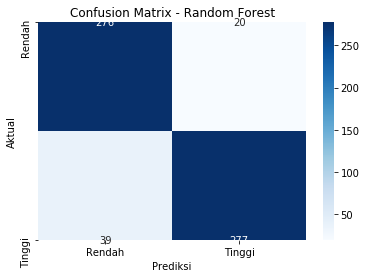

In [34]:
# model dan tebakan yang bener dan salah)
best = hasil_clf.sort_values("F1", ascending=False).iloc[0]["Model"]
print("Model terbaik (F1):", best)
print(classification_report(y_test, preds[best], target_names=["Rendah","Tinggi"]))
sns.heatmap(confusion_matrix(y_test, preds[best]), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rendah","Tinggi"], yticklabels=["Rendah","Tinggi"])
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title(f"Confusion Matrix - {best}"); plt.show()

Hasilnya Random Forest accuracy 0,90. Kelas Rendah precision 0,88 dan recall 0,93, kelas Tinggi precision 0,93 dan recall 0,88. Artinya model lebih sering meloloskan kasus Tinggi (recall 0,88) daripada salah menuduh (precision 0,93).

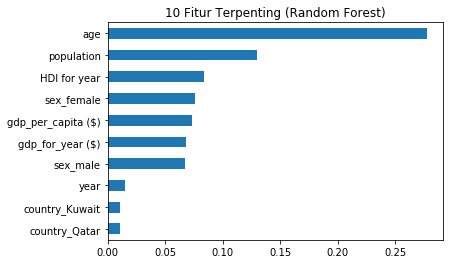

In [35]:
rf = fitted["Random Forest"]
ohe = rf.named_steps["prep"].named_transformers_["nom"]
cat_names = [f"{c}_{v}" for c, vals in zip(nom_cols, ohe.categories_) for v in vals]
names = num_cols + cat_names + ord_cols
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values().tail(10)
imp.plot(kind="barh", title="10 Fitur Terpenting (Random Forest)"); plt.show()

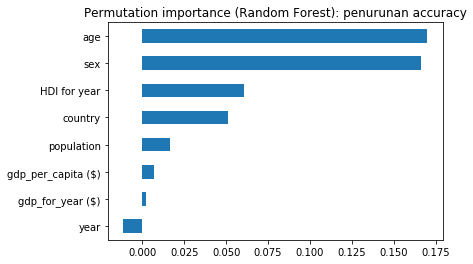

age                   0.170
sex                   0.166
HDI for year          0.061
country               0.051
population            0.017
gdp_per_capita ($)    0.007
gdp_for_year ($)      0.002
year                 -0.011
dtype: float64


In [36]:
def perm_imp(pipe, X_te, y_te, n_ulang=5, seed=1):
    rng = np.random.RandomState(seed)
    skor_awal = accuracy_score(y_te, pipe.predict(X_te))
    hasil = {}
    for kol in X_te.columns:
        turun = []
        for _ in range(n_ulang):
            X_acak = X_te.copy()
            X_acak[kol] = rng.permutation(X_acak[kol].values)
            turun.append(skor_awal - accuracy_score(y_te, pipe.predict(X_acak)))
        hasil[kol] = np.mean(turun)
    return pd.Series(hasil)

pi = perm_imp(fitted[best], X_test, y_test)
pi.sort_values().plot(kind="barh", title=f"Permutation importance ({best}): penurunan accuracy")
plt.show()
print(pi.sort_values(ascending=False).round(3))

Importance bawaan itu bisa tidak adil sama kolom kategori yang nilainya banyak kayak country. Permutation importance ngukurnya di data uji, jadi nunjukin kolom yang beneran ngebantu buat data baru.

Hasilnya kolom paling atas di grafik dan di output adalah yang paling berpengaruh. Kolom yang turunannya mendekati 0 berarti hampir tidak dipakai model.

Dari output, age (0,170) dan sex (0,166) paling berpengaruh, lalu HDI (0,061) dan country (0,051). population, gdp_per_capita, dan gdp_for_year kecil (di bawah 0,02). year negatif (-0,011), artinya tidak membantu model. Ini cocok sama bar chart: laki-laki dan umur tua jelas beda, tahun tidak.

## 7. Regresi (target: angka suicides/100k pop)

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [38]:
# bikin 4 model regresi hitung MAE, RMSE, sama R2 tiap model
reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=1),
    "KNN": KNeighborsRegressor(n_neighbors=best_k),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=1),
}
rows, rpred = [], {}
for name, m in reg_models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_reg_train)
    p = pipe.predict(X_test); rpred[name] = p
    rows.append([name, mean_absolute_error(y_reg_test, p), np.sqrt(mean_squared_error(y_reg_test, p)), r2_score(y_reg_test, p)])

In [39]:
# perbandingan model regresi
hasil_reg = pd.DataFrame(rows, columns=["Model","MAE","RMSE","R2"]).round(3)
hasil_reg.sort_values("R2", ascending=False)

,Model,MAE,RMSE,R2
3,Random Forest,2.872,6.779,0.837
1,Decision Tree,5.260,9.581,0.675
2,KNN,4.772,10.289,0.625
0,Linear Regression,7.904,12.319,0.462


- MAE: rata-rata selisih antara tebakan dan angka aslinya, satuannya sama kayak target. Contohnya MAE Random Forest 2,872 berarti rata-rata meleset sekitar 2,9 per 100 ribu penduduk. Makin kecil makin bagus.
- RMSE: mirip MAE tapi kesalahan yang gede dihitung lebih berat. RMSE Random Forest 6,779 lebih besar dari MAE-nya, tandanya ada beberapa tebakan yang melesetnya jauh.
- R2: seberapa besar variasi angka asli yang bisa dijelasin model. R2 Random Forest 0,837 berarti sekitar 83,7% variasinya ketangkep. Nilai 1 itu sempurna, 0 sama aja kayak nebak rata-rata terus, dan kalau negatif berarti lebih jelek dari nebak rata-rata.

Model regresi terbaik (R2): Random Forest


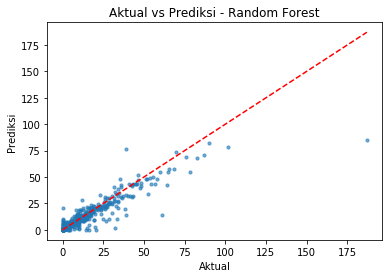

In [40]:
# grafik angka asli vs tebakan model terbaik
best_r = hasil_reg.sort_values("R2", ascending=False).iloc[0]["Model"]
print("Model regresi terbaik (R2):", best_r)
plt.scatter(y_reg_test, rpred[best_r], s=10, alpha=0.6)
lim = [0, max(y_reg_test.max(), rpred[best_r].max())]
plt.plot(lim, lim, "r--"); plt.xlabel("Aktual"); plt.ylabel("Prediksi"); plt.title(f"Aktual vs Prediksi - {best_r}"); plt.show()

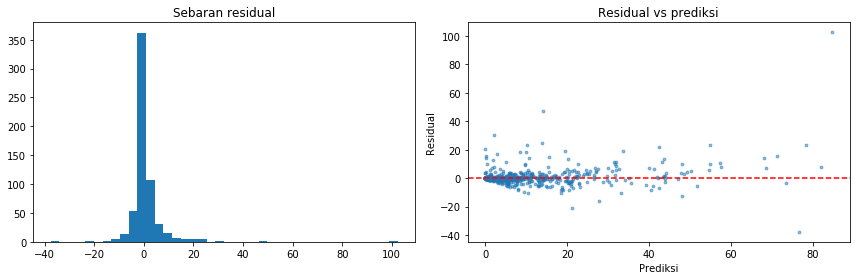

In [41]:
# grafik residual (angka asli dikurang tebakan)
residual = y_reg_test - rpred[best_r]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(residual, bins=40); ax[0].set_title("Sebaran residual")
ax[1].scatter(rpred[best_r], residual, s=8, alpha=0.5); ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Prediksi"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residual vs prediksi")
plt.tight_layout(); plt.show()

Model yang bagus residualnya kumpul di sekitar nol dan bentuknya kayak lonceng. Di grafik kedua, titik-titiknya nyebar acak di sekitar garis merah tanpa pola. Kalau ada pola, misalnya makin ke kanan makin melebar, berarti masih ada yang kelewat dari model.

Kesalahan terbesar biasanya ada di angka yang besar, jadi titik di sebelah kanan kemungkinan lebih nyebar. Itu sejalan sama RMSE yang lebih besar dari MAE.

In [42]:
# bandingkan MAE dan R2
rows = []
for name, m in reg_models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_reg_train)
    ptr, pte = pipe.predict(X_train), pipe.predict(X_test)
    rows.append([name, mean_absolute_error(y_reg_train, ptr), mean_absolute_error(y_reg_test, pte), r2_score(y_reg_train, ptr), r2_score(y_reg_test, pte)])
pd.DataFrame(rows, columns=["Model", "MAE train", "MAE test", "R2 train", "R2 test"]).round(3)

,Model,MAE train,MAE test,R2 train,R2 test
0,Linear Regression,7.381,7.904,0.555,0.462
1,Decision Tree,4.385,5.260,0.796,0.675
2,KNN,2.854,4.772,0.897,0.625
3,Random Forest,1.008,2.872,0.985,0.837


In [43]:
# cross validation 5 lipatan buat model regresi, pakai R2
rows = []
for name, m in reg_models.items():
    s = cross_val_score(Pipeline([("prep", prep), ("model", m)]), X_train, y_reg_train, cv=5, scoring="r2")
    rows.append([name, s.mean(), s.std()])
pd.DataFrame(rows, columns=["Model", "R2 CV rata-rata", "Std CV"]).round(3)

,Model,R2 CV rata-rata,Std CV
0,Linear Regression,0.509,0.030
1,Decision Tree,0.662,0.044
2,KNN,0.682,0.039
3,Random Forest,0.855,0.019


Biasanya Random Forest dan Decision Tree R2 latihnya jauh lebih tinggi dari R2 ujinya, karena pohon gampang ngapalin data. Kalau R2 CV dekat sama R2 uji dan Std CV kecil, hasilnya bisa dipercaya.

Hasilnya R2 latih vs uji: Random Forest 0,985 vs 0,837, KNN 0,897 vs 0,625 (selisih terbesar, 0,272), Decision Tree 0,796 vs 0,675, dan Linear Regression 0,555 vs 0,462. R2 CV Random Forest 0,855 dengan Std 0,019, dekat sama R2 uji, jadi bisa dipercaya.

## 8. Evaluasi Lebih Ketat: Split per Negara

In [44]:
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)
tr, te = next(gss.split(X, y_reg, groups=df["country"]))
Xg_train, Xg_test = X.iloc[tr], X.iloc[te]
yg_reg_train, yg_reg_test = y_reg.iloc[tr], y_reg.iloc[te]
med_g = yg_reg_train.median()
yg_train, yg_test = (yg_reg_train > med_g).astype(int), (yg_reg_test > med_g).astype(int)
print("Negara train:", df.iloc[tr]["country"].nunique(), "| Negara test:", df.iloc[te]["country"].nunique())

Negara train: 73 | Negara test: 19


In [45]:
# model klasifikasi dibandingkan sama hasil yang pembagian acak
rows = []
for name, m in clf_models.items():
    p = Pipeline([("prep", prep), ("model", m)]).fit(Xg_train, yg_train).predict(Xg_test)
    rows.append([name, accuracy_score(yg_test, p), f1_score(yg_test, p)])
hasil_g = pd.DataFrame(rows, columns=["Model","Accuracy","F1"]).round(3)
perbandingan = hasil_clf[["Model","Accuracy","F1"]].merge(hasil_g, on="Model", suffixes=(" (split acak)", " (split per negara)"))
perbandingan

,Model,Accuracy (split acak),F1 (split acak),Accuracy (split per negara),F1 (split per negara)
0,Logistic Regression,0.833,0.835,0.741,0.773
1,Decision Tree,0.873,0.879,0.829,0.858
2,KNN,0.894,0.894,0.799,0.833
3,Random Forest,0.904,0.904,0.821,0.843


In [46]:
# model regresi dilatih ulang pakai pembagian per negara
rows = []
for name, m in reg_models.items():
    p = Pipeline([("prep", prep), ("model", m)]).fit(Xg_train, yg_reg_train).predict(Xg_test)
    rows.append([name, mean_absolute_error(yg_reg_test, p), r2_score(yg_reg_test, p)])
pd.DataFrame(rows, columns=["Model","MAE","R2"]).round(3)

,Model,MAE,R2
0,Linear Regression,10.054,0.076
1,Decision Tree,6.329,0.441
2,KNN,7.044,0.352
3,Random Forest,5.671,0.556


Pakai GroupShuffleSplit, jadi negara yang ada di data test sama sekali tidak ada di data train (73 negara untuk train dan 19 untuk test).

Di split acak, satu negara punya baris di tahun 2010, 2011, dan 2012 dengan angka yang mirip. Bisa saja baris di data test punya "kembaran" di data train, jadi modelnya seperti menghafal negara, bukan belajar polanya. Dengan split per negara, model dites ke negara yang benar-benar baru.

Hasilnya skor turun di semua model. Di klasifikasi, Random Forest turun dari accuracy 0,904 jadi 0,821 (F1 0,904 jadi 0,843), KNN dari 0,894 jadi 0,799, Logistic Regression dari 0,833 jadi 0,741, dan Decision Tree turunnya paling kecil (0,873 jadi 0,829). Di split ini Decision Tree malah sedikit di atas Random Forest (accuracy 0,829 vs 0,821, F1 0,858 vs 0,843), jadi Random Forest tidak lagi jelas paling unggul. Di regresi, Random Forest tetap paling tinggi tapi R2 turun dari 0,837 jadi 0,556, Decision Tree 0,675 jadi 0,441, KNN 0,625 jadi 0,352, dan Linear Regression paling jatuh, 0,462 jadi 0,076. Jadi sebagian skor tinggi di split acak memang karena model hafal negara.

## 9. Clustering (segmentasi negara, tanpa target)

In [47]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

In [48]:
# data digabung per negara: rata-rata angka bunuh diri, rata-rata GDP per kapita, sama total populasi
neg = df.groupby("country").agg({"suicides/100k pop": "mean", "gdp_per_capita ($)": "mean", "population": "sum"}).reset_index()
neg.columns = ["country", "rate", "gdp_pc", "pop"]
print(neg.shape)

(92, 4)


In [49]:
# skalanya disamakan (K-Means ngitungnya pakai jarak)
Xc = StandardScaler().fit_transform(neg[["rate", "gdp_pc", "pop"]])

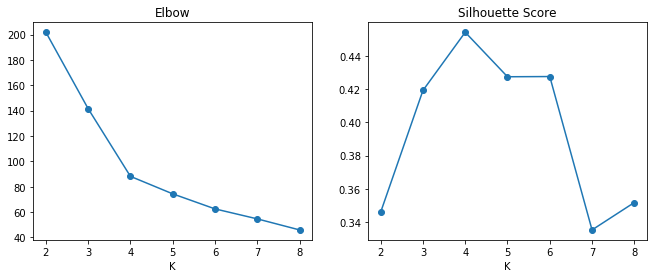

{2: 0.346, 3: 0.419, 4: 0.454, 5: 0.427, 6: 0.427, 7: 0.335, 8: 0.352}


In [50]:
# cari jumlah cluster (K) yang pas
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=1, n_init=10).fit(Xc)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xc, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow"); ax[0].set_xlabel("K")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("K")
plt.show()
print(dict(zip(ks, np.round(sil, 3))))

In [51]:
# hitung Silhouette-nya K=4
K = 4
km = KMeans(n_clusters=K, random_state=1, n_init=10).fit(Xc)
neg["KMeans"] = km.labels_
print("Silhouette K-Means:", round(silhouette_score(Xc, km.labels_), 4))

Silhouette K-Means: 0.4541


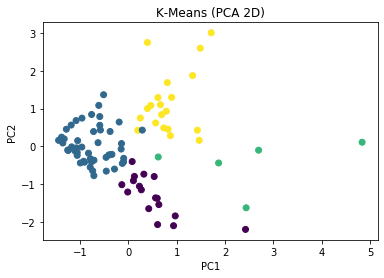

In [52]:
# hasil cluster digambar 2 dimensi pakai PCA
pc = PCA(n_components=2).fit_transform(Xc)
plt.scatter(pc[:,0], pc[:,1], c=km.labels_, cmap="viridis")
plt.title("K-Means (PCA 2D)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

In [53]:
print(neg.groupby("KMeans")[["rate","gdp_pc","pop"]].mean().round(1))
print(neg["KMeans"].value_counts())

        rate   gdp_pc          pop
KMeans                            
0       24.2  13052.1   35340888.2
1        5.5  13481.6   32571794.1
2       14.1  28302.7  502365369.2
3       11.7  61331.0   58113005.0
1    50
3    20
0    17
2     5
Name: KMeans, dtype: int64


In [54]:
# contoh negara di tiap cluster (8 yang pertama)
for c in sorted(neg["KMeans"].unique()):
    print(f"Cluster {c}:", ", ".join(neg[neg["KMeans"]==c]["country"].head(8)))

Cluster 0: Belarus, Croatia, Cuba, Czech Republic, Estonia, Guyana, Hungary, Kazakhstan
Cluster 1: Albania, Antigua and Barbuda, Argentina, Armenia, Aruba, Bahamas, Bahrain, Barbados
Cluster 2: Brazil, Japan, Mexico, Russian Federation, United States
Cluster 3: Australia, Austria, Belgium, Canada, Denmark, Finland, France, Germany


In [55]:
# cek 10 negara teratas masuk cluster yang mana
top10 = df.groupby("country")["suicides/100k pop"].mean().sort_values(ascending=False).head(10).index
neg[neg["country"].isin(top10)][["country", "rate", "KMeans"]].sort_values("rate", ascending=False)

,country,rate,KMeans
67,Republic of Korea,41.014167,0
79,Suriname,34.242222,0
49,Lithuania,32.695833,0
37,Guyana,31.127222,0
10,Belarus,26.305833,0
38,Hungary,25.753333,0
69,Russian Federation,25.122222,2
45,Kazakhstan,24.599722,0
76,Slovenia,22.971944,0
48,Latvia,22.660278,0


Sel di atas buat ngecek dugaan di bagian EDA: lihat kolom KMeans di output, 10 negara teratas masuk ke cluster yang mana.

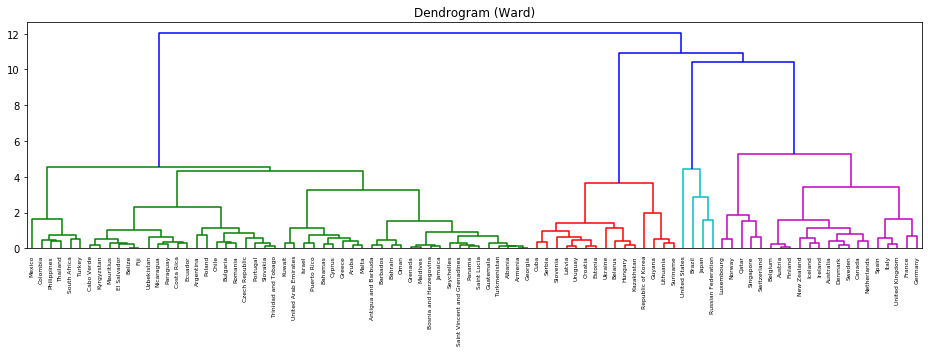

In [56]:
# Hierarchical Clustering metode Ward
Z = linkage(Xc, method="ward")
plt.figure(figsize=(13,5))
dendrogram(Z, labels=neg["country"].values, leaf_rotation=90, leaf_font_size=6)
plt.title("Dendrogram (Ward)"); plt.tight_layout(); plt.show()

In [57]:
# dipotong jadi 4 cluster biar bisa dibandingin sama K-Means, terus hitung Silhouette dan rata-rata tiap cluster
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Xc)
neg["HC"] = hc.labels_
print("Silhouette Hierarchical:", round(silhouette_score(Xc, hc.labels_), 4))
print(neg.groupby("HC")[["rate","gdp_pc","pop"]].mean().round(1))

Silhouette Hierarchical: 0.4499
    rate   gdp_pc          pop
HC                            
0   11.5  59951.4   61610328.0
1    5.9  13229.2   37649169.9
2   25.4  12422.3   30864727.1
3   16.3  32716.9  547231780.0


Data digabung per negara (rata-rata angka bunuh diri, rata-rata GDP per kapita, dan total populasi), di-scaling, lalu dipakai K-Means dan Hierarchical Clustering (metode Ward). Jumlah cluster dicek pakai Elbow dan Silhouette, dan hasilnya digambar pakai PCA 2 dimensi.

Hasilnya Silhouette tertinggi ada di K=4 (0,454), lebih tinggi dari K=3 (0,419) dan K=5 (0,427), jadi aku pakai K=4. Silhouette K-Means 0,454 dan Hierarchical 0,450, skornya hampir sama. Empat segmen (dari tabel Hierarchical):
- Segmen 1: angka rendah (5,9) dengan GDP per kapita 13.229.
- Segmen 2: angka paling tinggi (25,4) dengan GDP per kapita 12.422.
- Segmen 0: GDP per kapita paling tinggi (59.951) dengan angka 11,5.
- Segmen 3: angka 16,3 dengan GDP per kapita 32.717 dan populasi total jauh paling besar (547 juta).

Segmen 1 dan 2 GDP nya sama sekitar 13 ribu tapi angkanya jauh beda (5,9 dan 25,4), jadi GDP saja tidak cukup untuk menjelaskan perbedaan angka antar negara.

## 10. Kesimpulan

1. Data yang kupakai berisi 3.060 baris dan 92 negara dari tahun 2010 sampai 2012. Satu baris mewakili satu kelompok (negara, tahun, jenis kelamin, dan umur), bukan satu orang.
2. Dari EDA, angka bunuh diri laki-laki (18,01 per 100 ribu penduduk) sekitar empat kali lipat perempuan (4,42), dan paling tinggi di kelompok umur 75+ (20,14). Angkanya hampir sama di tiga tahun itu. Angka ini juga hampir tidak berhubungan lurus dengan populasi dan GDP.
3. Di klasifikasi risiko Tinggi atau Rendah, Random Forest paling bagus dengan accuracy 0,904 dan F1 0,904. Kolom yang paling berpengaruh buat modelnya adalah age dan sex. Random Forest paling overfit (skor latihnya 1,000), tapi hasil cross validation-nya stabil (0,915) dan skor ujinya tetap yang tertinggi. Di regresi, Random Forest juga paling bagus (R2 0,837 dan MAE 2,872).
4. Waktu data kupisah per negara, skor semua model turun. Accuracy Random Forest jadi 0,821 dan R2-nya jadi 0,556, bahkan Decision Tree sedikit lebih tinggi di klasifikasi (0,829). Artinya sebagian skor tinggi tadi muncul karena model menghafal negara, dan model masih sulit menebak negara yang benar-benar baru.
5. Di clustering, K=4 memberi Silhouette paling tinggi (0,454), dan Hierarchical Clustering hasilnya hampir sama (0,450). Ada dua segmen yang GDP per kapitanya sama-sama sekitar 13 ribu tapi angkanya jauh beda (5,9 dan 25,4), jadi GDP saja tidak cukup untuk menjelaskan perbedaan antar negara.